# Short-term electric load forecasting – office floor (CU-BEMS)

Data: CU-BEMS dataset (Chulalongkorn University, Bangkok) – 1-minute readings of AC, lighting
and plug loads plus temperature/humidity/lux for each zone of a 7-floor office building.
I use floor 6, 2019.

Target: total electric load of the floor, **1 hour ahead**.

Note on my first version: I originally had the target column (`z1_AC1`) inside the feature list,
which gave R² ≈ 0.99 – but that's just the model reading the answer. This version only uses
information available *before* the forecast time.

In [1]:
import zipfile, io
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

In [2]:
# Data: the course zip (GroupF_Electric_Load_Data*.zip) next to the notebook, or a plain 2019Floor6.csv.
# Depending on how it was downloaded, the CSV sits directly in the zip or in a nested Data_2019.zip.
CSV_PATH = Path("2019Floor6.csv")

def read_floor6():
    if CSV_PATH.exists():
        return pd.read_csv(CSV_PATH)
    zip_path = next(Path(".").glob("*Electric_Load*.zip"))
    with zipfile.ZipFile(zip_path) as outer:
        names = outer.namelist()
        hit = [n for n in names if n.endswith("2019Floor6.csv")]
        if hit:
            return pd.read_csv(outer.open(hit[0]))
        inner_name = next(n for n in names if n.endswith("Data_2019.zip"))
        inner = zipfile.ZipFile(io.BytesIO(outer.read(inner_name)))
        csv = next(n for n in inner.namelist() if n.endswith("2019Floor6.csv"))
        return pd.read_csv(inner.open(csv))

raw = read_floor6()
raw["Date"] = pd.to_datetime(raw["Date"], errors="coerce")
raw = raw.dropna(subset=["Date"]).set_index("Date").sort_index()
raw.shape

(424168, 29)

In [3]:
# total floor load = sum of all kW columns, resampled to hourly mean
kw_cols = [c for c in raw.columns if c.endswith("(kW)")]
temp_cols = [c for c in raw.columns if c.endswith("(degC)")]

hourly = pd.DataFrame({
    "load_kw": raw[kw_cols].sum(axis=1),
    "temp_c": raw[temp_cols].mean(axis=1),
}).resample("h").mean().interpolate(limit=3).dropna()

print(len(kw_cols), "kW channels ->", hourly.shape)

17 kW channels -> (5519, 2)


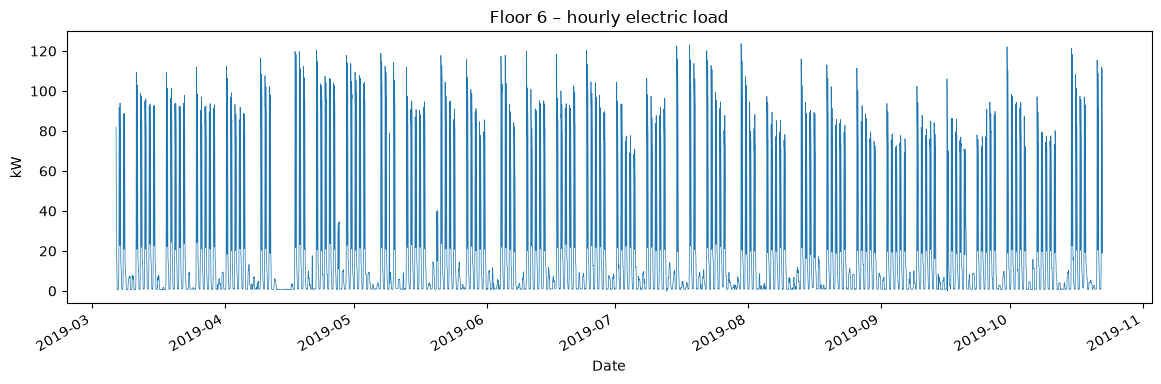

In [4]:
fig, ax = plt.subplots(figsize=(14, 4))
hourly["load_kw"].plot(ax=ax, lw=0.5)
ax.set_ylabel("kW"); ax.set_title("Floor 6 – hourly electric load")
plt.show()

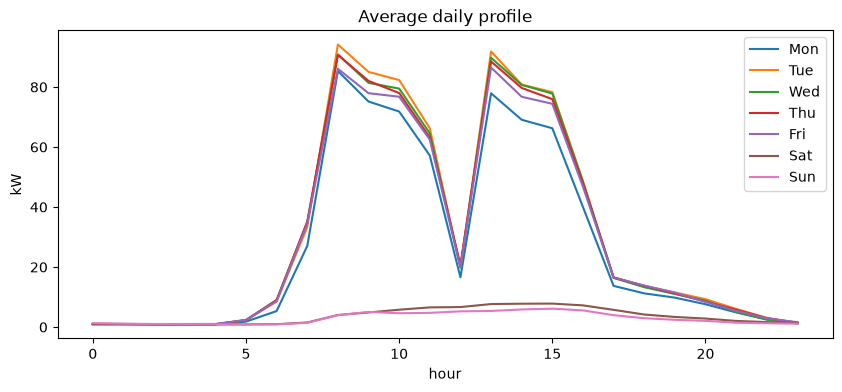

In [5]:
# typical week profile: big working-hours peak, almost nothing at night and weekends
prof = hourly.groupby([hourly.index.day_of_week, hourly.index.hour])["load_kw"].mean().unstack(0)
prof.columns = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
prof.plot(figsize=(10, 4)); plt.xlabel("hour"); plt.ylabel("kW"); plt.title("Average daily profile")
plt.show()

## Features

Everything here is known at time *t-1*: past loads (lags), rolling mean, calendar.

In [6]:
def build_features(h):
    f = pd.DataFrame(index=h.index)
    for lag in [1, 2, 3, 24, 168]:
        f[f"lag_{lag}"] = h["load_kw"].shift(lag)
    f["roll_24"] = h["load_kw"].shift(1).rolling(24).mean()
    f["temp_lag_1"] = h["temp_c"].shift(1)
    f["hour"] = h.index.hour
    f["dow"] = h.index.day_of_week
    f["weekend"] = (f["dow"] >= 5).astype(int)
    f["y"] = h["load_kw"]
    return f.dropna()

data = build_features(hourly)
split = int(len(data) * 0.8)
train, test = data.iloc[:split], data.iloc[split:]
X_cols = [c for c in data.columns if c != "y"]

In [7]:
model = XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=5,
                     subsample=0.8, colsample_bytree=0.8, random_state=42)
model.fit(train[X_cols], train["y"])
pred = model.predict(test[X_cols])

def scores(y, p):
    return {"MAE [kW]": mean_absolute_error(y, p),
            "RMSE [kW]": np.sqrt(mean_squared_error(y, p)),
            "R²": r2_score(y, p)}

pd.DataFrame({
    "Same hour last week": scores(test["y"], test["lag_168"]),
    "Previous hour": scores(test["y"], test["lag_1"]),
    "XGBoost": scores(test["y"], pred),
}).T.round(3)

,MAE [kW],RMSE [kW],R²
Same hour last week,4.501,11.715,0.855
Previous hour,9.323,19.542,0.596
XGBoost,1.983,4.484,0.979


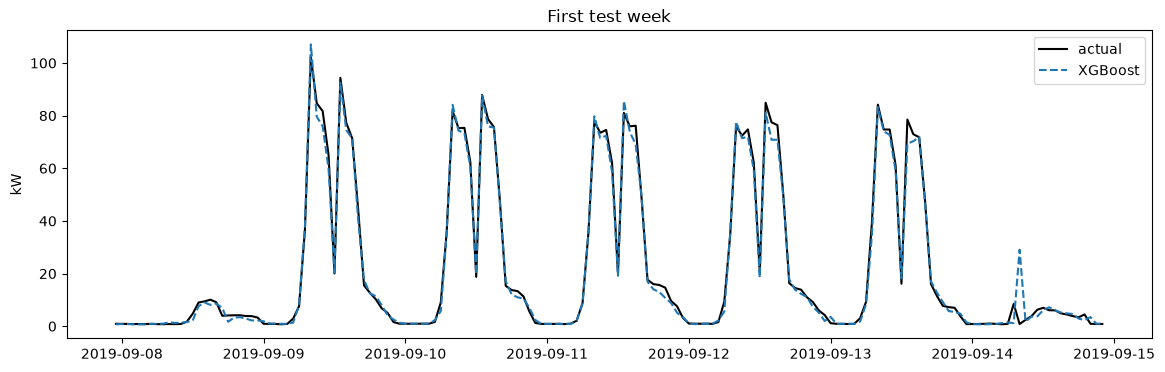

In [8]:
week = slice(0, 24 * 7)
plt.figure(figsize=(14, 4))
plt.plot(test.index[week], test["y"].values[week], color="black", label="actual")
plt.plot(test.index[week], pred[week], ls="--", label="XGBoost")
plt.ylabel("kW"); plt.legend(); plt.title("First test week")
plt.show()

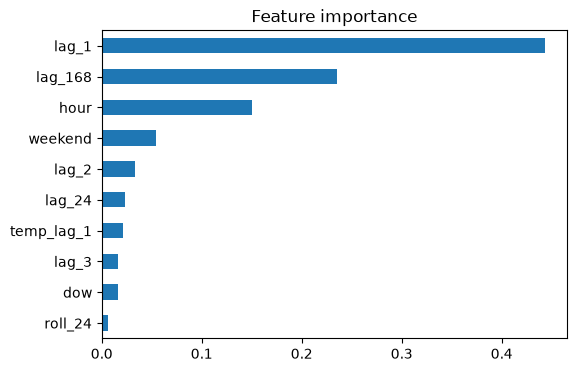

In [9]:
pd.Series(model.feature_importances_, index=X_cols).sort_values().plot.barh(figsize=(6, 4))
plt.title("Feature importance"); plt.show()

The 1-hour lag and the hour-of-day carry most of the information, as expected for an office
that follows a fixed schedule. The weekly lag helps on Mondays and after holidays.